In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Imports
import os
import numpy as np
import random
from PIL import Image, ImageEnhance
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dropout, Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16, ResNet50
from sklearn.utils import shuffle
import matplotlib.pyplot as plt
import json  # for saving/loading label map
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
# Directories
train_dir = '/content/drive/MyDrive/MRI Images/Training/'
test_dir = '/content/drive/MyDrive/MRI Images/Testing/'
val_dir = '/content/drive/MyDrive/MRI Images/Validation/'

# Load and shuffle datasets
def load_dataset(dir_path):
    paths, labels = [], []
    for label in os.listdir(dir_path):
        for image in os.listdir(os.path.join(dir_path, label)):
            paths.append(os.path.join(dir_path, label, image))
            labels.append(label)
    return shuffle(paths, labels)

train_paths, train_labels = load_dataset(train_dir)
test_paths, test_labels = load_dataset(test_dir)
val_paths, val_labels = load_dataset(val_dir)

# Save label map (sorted for consistency)
label_map_path = '/content/drive/MyDrive/MRI Images/label_map.json'
unique_labels = sorted(os.listdir(train_dir))
with open(label_map_path, "w") as f:
    json.dump(unique_labels, f)


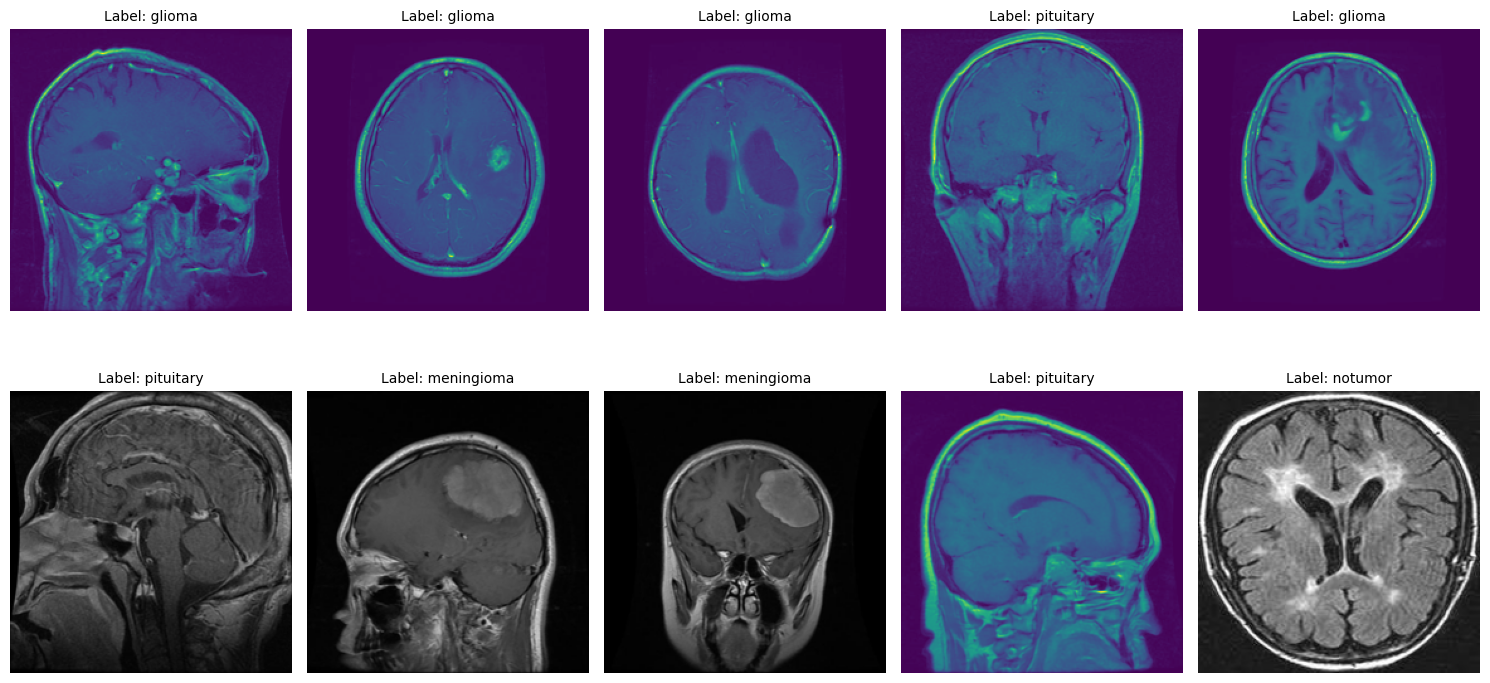

In [ ]:
# Data visualization
random_indices = random.sample(range(len(train_paths)), 10)
fig, axes = plt.subplots(2, 5, figsize=(15, 8))
axes = axes.ravel()
for i, idx in enumerate(random_indices):
    img = Image.open(train_paths[idx]).resize((224, 224))
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"Label: {train_labels[idx]}", fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:
# Preprocessing
IMAGE_SIZE = 128

def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    return np.array(image) / 255.0

def open_images(paths):
    images = []
    for path in paths:
        img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        images.append(augment_image(img))
    return np.array(images)

def encode_label(labels):
    return np.array([unique_labels.index(label) for label in labels])

def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)
            batch_labels = encode_label(labels[i:i + batch_size])
            yield batch_images, batch_labels


In [ ]:
# Validation data (preprocessed)
def preprocess_image(path):
    img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
    return np.array(img) / 255.0

val_images = np.array([preprocess_image(p) for p in val_paths])
val_labels_encoded = encode_label(val_labels)

# Train
batch_size = 20
epochs = 5
steps = len(train_paths) // batch_size

early_stop = EarlyStopping(
    monitor='val_loss',     # Stop when validation loss stops improving
    patience=3,             # Wait for 3 epochs without improvement
    restore_best_weights=True,  # Restore model weights from the best epoch
    verbose=1
)

# Build VGG16-based model
vgg_base = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet')
for layer in vgg_base.layers:
    layer.trainable = False
for i in [-2, -3, -4]:
    vgg_base.layers[i].trainable = True

vgg_model = Sequential([
    Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
    vgg_base,
    Flatten(),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(len(unique_labels), activation='softmax')
])

vgg_model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])


history = vgg_model.fit(
    datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
    epochs=epochs,
    steps_per_epoch=steps,
    validation_data=(val_images, val_labels_encoded),
    callbacks=[early_stop]  # â† Add this line
)

Epoch 1/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 1702s 7s/step - loss: 0.9127 - sparse_categorical_accuracy: 0.6169 - val_loss: 0.3555 - val_sparse_categorical_accuracy: 0.8745
Epoch 2/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 24s 105ms/step - loss: 0.3400 - sparse_categorical_accuracy: 0.8757 - val_loss: 0.3312 - val_sparse_categorical_accuracy: 0.8786
Epoch 3/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 24s 105ms/step - loss: 0.2405 - sparse_categorical_accuracy: 0.9080 - val_loss: 0.2386 - val_sparse_categorical_accuracy: 0.9198
Epoch 4/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 24s 107ms/step - loss: 0.1802 - sparse_categorical_accuracy: 0.9329 - val_loss: 0.2256 - val_sparse_categorical_accuracy: 0.9259
Epoch 5/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 23s 101ms/step - loss: 0.1242 - sparse_categorical_accuracy: 0.9494 - val_loss: 0.1897 - val_sparse_categorical_accuracy: 0.9414
Restoring model weights from the end of the best epoch: 5.


In [ ]:
# Build ResNet50-based model
resnet_base = ResNet50(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet')
for layer in resnet_base.layers:
    layer.trainable = False
for layer in resnet_base.layers[-10:]:  # Unfreeze last 10 layers
    layer.trainable = True

resnet_model = Sequential([
    Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
    resnet_base,
    GlobalAveragePooling2D(),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(len(unique_labels), activation='softmax')
])

resnet_model.compile(optimizer=Adam(learning_rate=0.0001),
                     loss='sparse_categorical_crossentropy',
                     metrics=['sparse_categorical_accuracy'])

# Train ResNet model
print("\nTraining ResNet50 model...")
resnet_history = resnet_model.fit(
    datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
    epochs=epochs,
    steps_per_epoch=steps,
    validation_data=(val_images, val_labels_encoded),
    callbacks=[early_stop]
)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

Training ResNet50 model...
Epoch 1/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 50s 155ms/step - loss: 1.0911 - sparse_categorical_accuracy: 0.5356 - val_loss: 1.5858 - val_sparse_categorical_accuracy: 0.3951
Epoch 2/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 23s 100ms/step - loss: 0.6777 - sparse_categorical_accuracy: 0.7211 - val_loss: 0.6735 - val_sparse_categorical_accuracy: 0.6574
Epoch 3/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 23s 102ms/step - loss: 0.5641 - sparse_categorical_accuracy: 0.7674 - val_loss: 0.5283 - val_sparse_categorical_accuracy: 0.7613
Epoch 4/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 23s 101ms/step - loss: 0.5204 - sparse_categorical_accuracy: 0.7872 - val_loss: 0.4409 - val_sparse_categorical_accuracy: 0.8292
Epoch 5/5
227/227 ━━━━━━━━━━━━━━━━━━━━ 22s 98ms/step - loss: 0.4987 - sparse_categorical_accuracy: 0.7947 - val_loss: 0.4668 - val_sparse_categorical_accuracy: 0.8086
Restoring model weights from the end of the best epoch: 4.


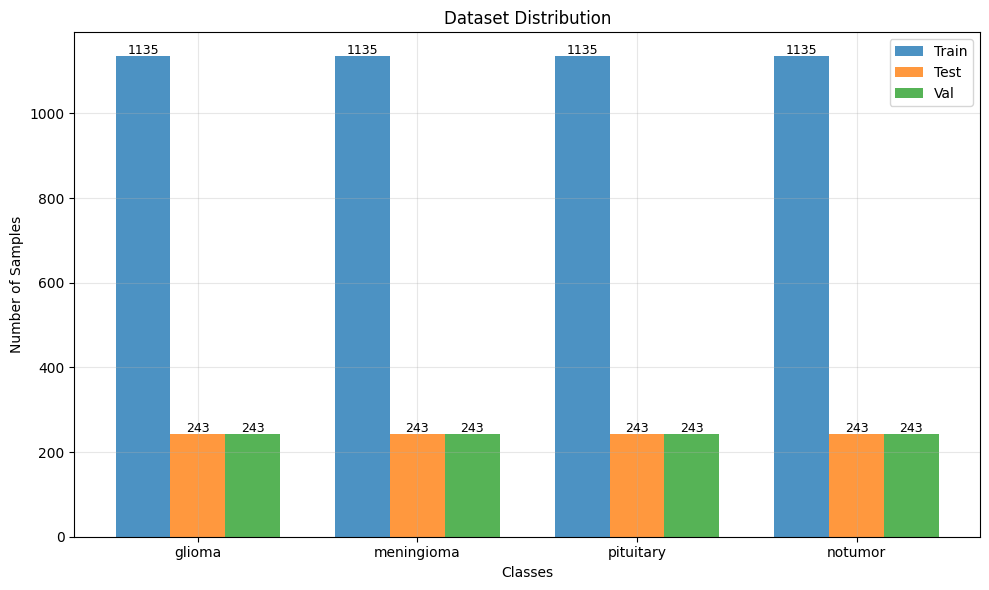

Total: Train=4540, Test=972, Val=972


In [ ]:
# Count samples
def count_samples(directory):
    return {cls: len(os.listdir(os.path.join(directory, cls))) for cls in os.listdir(directory)}

train_counts = count_samples(train_dir)
test_counts = count_samples(test_dir)
val_counts = count_samples(val_dir)

# Prepare data
classes = list(train_counts.keys())
train_nums = [train_counts[c] for c in classes]
test_nums = [test_counts[c] for c in classes]
val_nums = [val_counts[c] for c in classes]

# Plot
plt.figure(figsize=(10, 6))
x = np.arange(len(classes))

plt.bar(x - 0.25, train_nums, 0.25, label='Train', alpha=0.8)
plt.bar(x, test_nums, 0.25, label='Test', alpha=0.8)
plt.bar(x + 0.25, val_nums, 0.25, label='Val', alpha=0.8)

# Add numbers on bars
for i, (t, te, v) in enumerate(zip(train_nums, test_nums, val_nums)):
    plt.text(i-0.25, t+5, str(t), ha='center', fontsize=9)
    plt.text(i, te+5, str(te), ha='center', fontsize=9)
    plt.text(i+0.25, v+5, str(v), ha='center', fontsize=9)



plt.xlabel('Classes')
plt.ylabel('Number of Samples')
plt.title('Dataset Distribution')
plt.xticks(x, classes)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total: Train={sum(train_nums)}, Test={sum(test_nums)}, Val={sum(val_nums)}")


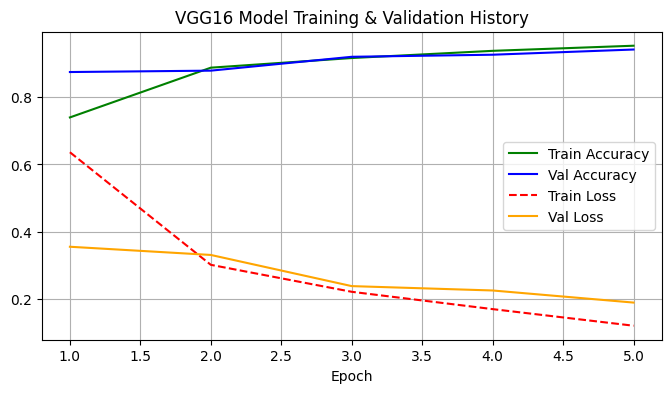

In [ ]:
# Training history plots (VGG16)
plt.figure(figsize=(8,4))
plt.grid(True)

epochs = range(1, len(history.history['loss']) + 1)

plt.plot(epochs, history.history['sparse_categorical_accuracy'], 'g-', label='Train Accuracy')
plt.plot(epochs, history.history['val_sparse_categorical_accuracy'], 'b-', label='Val Accuracy')
plt.plot(epochs, history.history['loss'], 'r--', label='Train Loss')
plt.plot(epochs, history.history['val_loss'], 'orange', label='Val Loss')

plt.title('VGG16 Model Training & Validation History')
plt.xlabel('Epoch')
plt.legend()
plt.show()


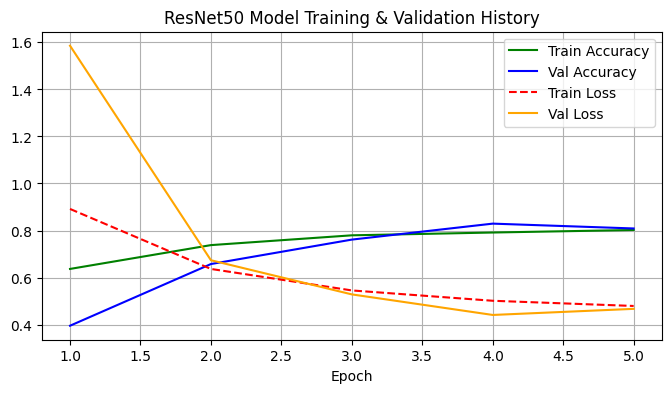

In [ ]:
# Training history plots (ResNet)
plt.figure(figsize=(8,4))
plt.grid(True)

epochs_resnet = range(1, len(resnet_history.history['loss']) + 1)

plt.plot(epochs_resnet, resnet_history.history['sparse_categorical_accuracy'], 'g-', label='Train Accuracy')
plt.plot(epochs_resnet, resnet_history.history['val_sparse_categorical_accuracy'], 'b-', label='Val Accuracy')
plt.plot(epochs_resnet, resnet_history.history['loss'], 'r--', label='Train Loss')
plt.plot(epochs_resnet, resnet_history.history['val_loss'], 'orange', label='Val Loss')

plt.title('ResNet50 Model Training & Validation History')
plt.xlabel('Epoch')
plt.legend()
plt.show()



31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step
VGG16 Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.91      0.93       243
           1       0.90      0.90      0.90       243
           2       0.99      0.99      0.99       243
           3       0.96      1.00      0.98       243

    accuracy                           0.95       972
   macro avg       0.95      0.95      0.95       972
weighted avg       0.95      0.95      0.95       972

VGG16 Confusion Matrix:
[[222  21   0   0]
 [ 12 218   3  10]
 [  2   1 240   0]
 [  0   1   0 242]]


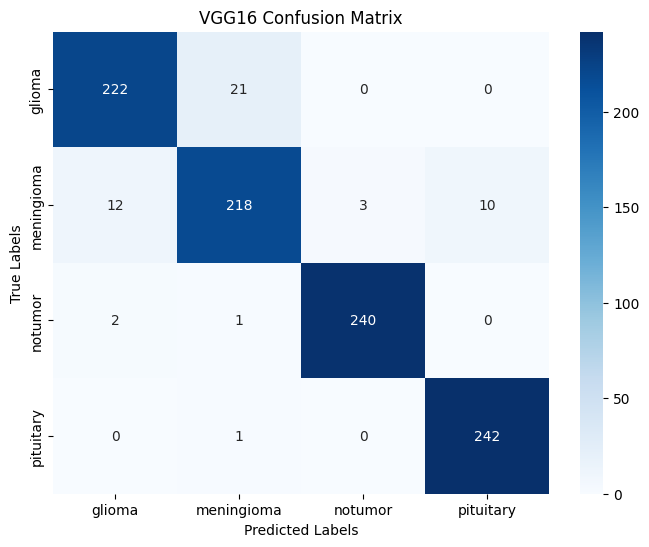

In [ ]:
# Evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns
from sklearn.preprocessing import label_binarize

test_images = open_images(test_paths)
test_labels_encoded = encode_label(test_labels)
predictions = vgg_model.predict(test_images)

print("VGG16 Classification Report:")
print(classification_report(test_labels_encoded, np.argmax(predictions, axis=1)))

conf_matrix = confusion_matrix(test_labels_encoded, np.argmax(predictions, axis=1))
print("VGG16 Confusion Matrix:")
print(conf_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=unique_labels, yticklabels=unique_labels)
plt.title("VGG16 Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


31/31 ━━━━━━━━━━━━━━━━━━━━ 9s 150ms/step

ResNet50 Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.66      0.73       243
           1       0.63      0.58      0.60       243
           2       0.84      0.97      0.90       243
           3       0.83      0.93      0.88       243

    accuracy                           0.78       972
   macro avg       0.78      0.78      0.78       972
weighted avg       0.78      0.78      0.78       972

ResNet50 Confusion Matrix:
[[160  71   2  10]
 [ 32 140  40  31]
 [  1   1 235   6]
 [  4  11   2 226]]


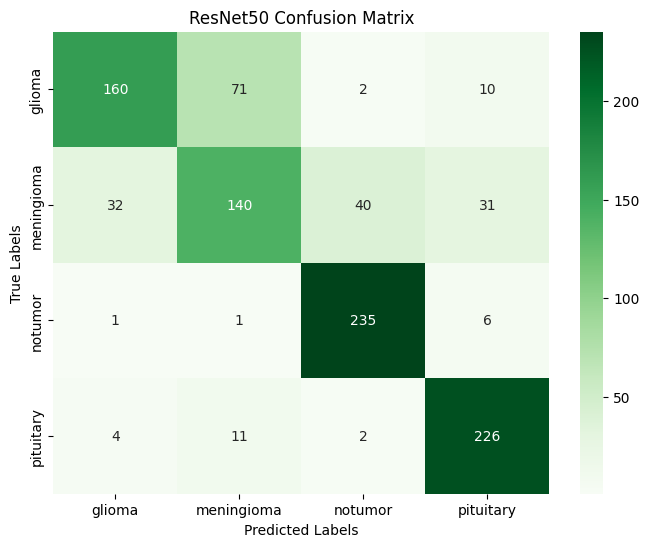

In [ ]:
# ResNet evaluation
resnet_predictions = resnet_model.predict(test_images)

print("\nResNet50 Classification Report:")
print(classification_report(test_labels_encoded, np.argmax(resnet_predictions, axis=1)))

resnet_conf_matrix = confusion_matrix(test_labels_encoded, np.argmax(resnet_predictions, axis=1))
print("ResNet50 Confusion Matrix:")
print(resnet_conf_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(resnet_conf_matrix, annot=True, fmt="d", cmap="Greens", xticklabels=unique_labels, yticklabels=unique_labels)
plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step


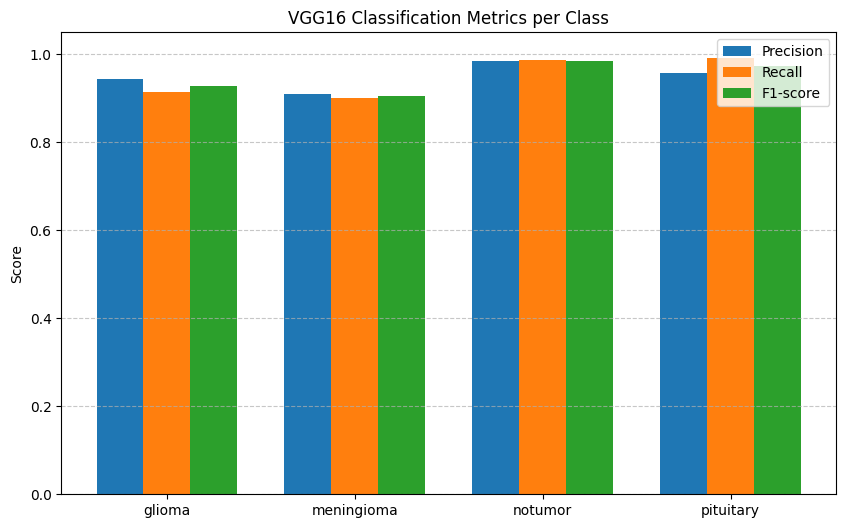

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# --- Your existing evaluation code ---
test_images = open_images(test_paths)
test_labels_encoded = encode_label(test_labels)
predictions = vgg_model.predict(test_images)

# Get report as dictionary
report = classification_report(
    test_labels_encoded,
    np.argmax(predictions, axis=1),
    target_names=unique_labels,
    output_dict=True
)

# Remove 'accuracy', 'macro avg', 'weighted avg'
metrics_data = {label: [report[label]['precision'],
                        report[label]['recall'],
                        report[label]['f1-score']]
                for label in unique_labels}

# Convert to arrays for plotting
labels = list(metrics_data.keys())
metrics = ['Precision', 'Recall', 'F1-score']
values = np.array(list(metrics_data.values()))

# --- Grouped bar chart ---
x = np.arange(len(labels))  # label locations
width = 0.25  # bar width

plt.figure(figsize=(10, 6))
for i, metric in enumerate(metrics):
    plt.bar(x + i*width - width, values[:, i], width, label=metric)

plt.xticks(x, labels)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("VGG16 Classification Metrics per Class")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()



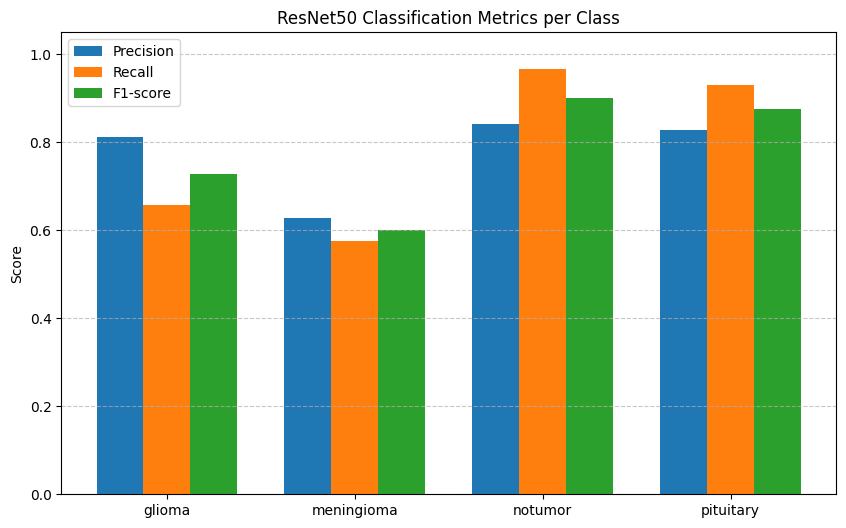

In [ ]:
# ResNet metrics
resnet_report = classification_report(
    test_labels_encoded,
    np.argmax(resnet_predictions, axis=1),
    target_names=unique_labels,
    output_dict=True
)

resnet_metrics_data = {label: [resnet_report[label]['precision'],
                               resnet_report[label]['recall'],
                               resnet_report[label]['f1-score']]
                       for label in unique_labels}

resnet_values = np.array(list(resnet_metrics_data.values()))

plt.figure(figsize=(10, 6))
for i, metric in enumerate(metrics):
    plt.bar(x + i*width - width, resnet_values[:, i], width, label=metric)

plt.xticks(x, labels)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("ResNet50 Classification Metrics per Class")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


In [ ]:
# Save model
vgg_model.save('/content/drive/MyDrive/MRI Images/vgg_model.keras')
resnet_model.save('/content/drive/MyDrive/MRI Images/resnet_model.keras')


In [ ]:
from keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
import json

# Load label map
with open("/content/drive/MyDrive/MRI Images/label_map.json", "r") as f:
    class_labels = json.load(f)

# Load trained model
vggmodel = load_model('/content/drive/MyDrive/MRI Images/vgg_model.keras', compile=False)
resnetmodel = load_model('/content/drive/MyDrive/MRI Images/resnet_model.keras', compile=False)

def detect_and_display(img_path, model, image_size=128):
    try:
        img = load_img(img_path, target_size=(image_size, image_size))
        img_array = img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        predictions = model.predict(img_array)
        predicted_class_index = np.argmax(predictions, axis=1)[0]
        confidence_score = np.max(predictions, axis=1)[0]
        predicted_label = class_labels[predicted_class_index]

        result = "No Tumor" if predicted_label == 'notumor' else f"Tumor: {predicted_label}"

        plt.imshow(load_img(img_path))
        plt.axis('off')
        plt.title(f"{result} (Confidence: {confidence_score * 100:.2f}%)")
        plt.show()

    except Exception as e:
        print("Error processing the image:", str(e))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


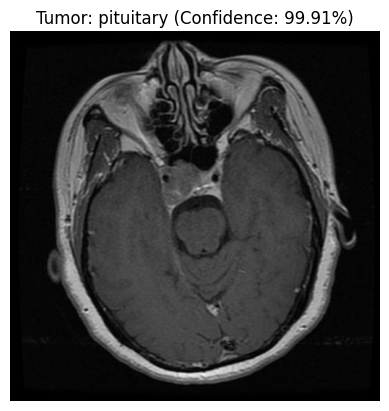

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


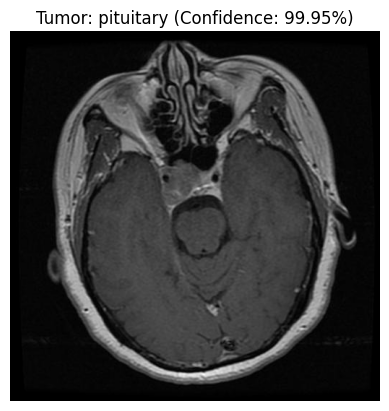

In [ ]:
detect_and_display('/content/drive/MyDrive/MRI Images/Testing/pituitary/Te-pi_0014.jpg', vggmodel)
detect_and_display('/content/drive/MyDrive/MRI Images/Testing/pituitary/Te-pi_0014.jpg', resnetmodel)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


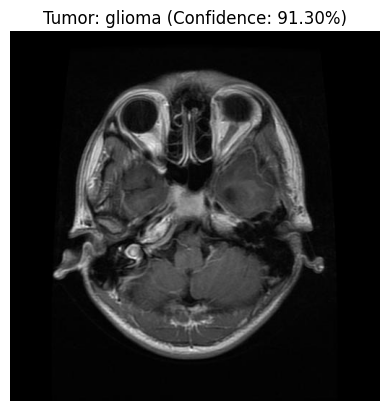

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


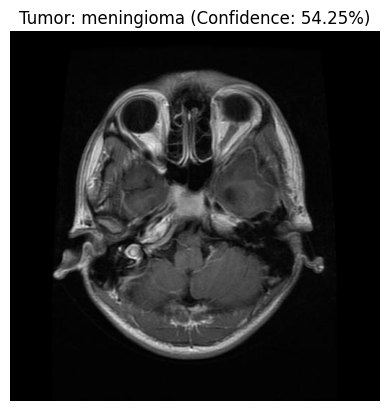

In [ ]:
detect_and_display('/content/drive/MyDrive/MRI Images/Testing/glioma/Te-glTr_0003.jpg', vggmodel)
detect_and_display('/content/drive/MyDrive/MRI Images/Testing/glioma/Te-glTr_0003.jpg', resnetmodel)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


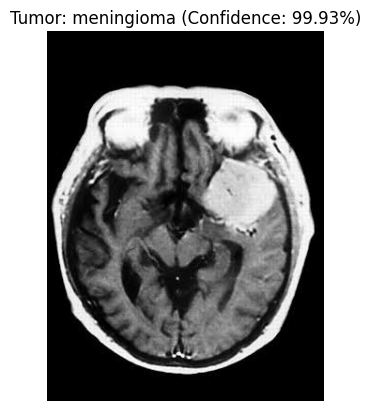

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


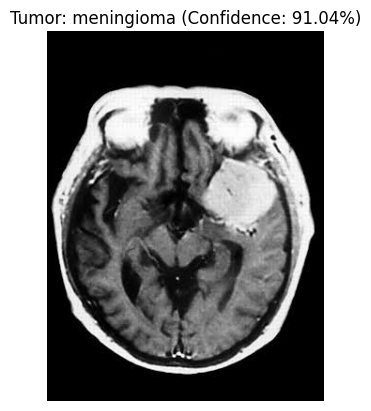

In [ ]:
detect_and_display('/content/drive/MyDrive/MRI Images/Testing/meningioma/Te-meTr_0005.jpg', vggmodel)
detect_and_display('/content/drive/MyDrive/MRI Images/Testing/meningioma/Te-meTr_0005.jpg', resnetmodel)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


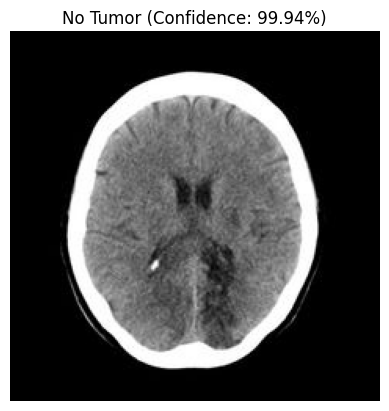

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


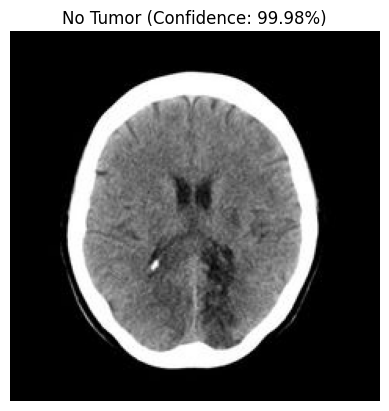

In [ ]:
detect_and_display('/content/drive/MyDrive/MRI Images/Testing/notumor/Te-no_0012.jpg', vggmodel)
detect_and_display('/content/drive/MyDrive/MRI Images/Testing/notumor/Te-no_0012.jpg', resnetmodel)